Epoch: 2000 Training error: 230019331.50112805 Testing_error: 49501035.2675601 Parameters: [28224.035188119324, 10321.497347350689]
Epoch: 4000 Training error: 230027671.0738759 Testing_error: 48988830.63027946 Parameters: [28547.325955907945, 10265.941235107473]
Epoch: 6000 Training error: 230027928.32978815 Testing_error: 48982508.49165447 Parameters: [28551.41877704359, 10265.237901597646]
Epoch: 8000 Training error: 230027931.61092597 Testing_error: 48982428.48017515 Parameters: [28551.47059165303, 10265.228997482393]
Epoch: 10000 Training error: 230027931.65246868 Testing_error: 48982427.46724403 Parameters: [28551.471247619513, 10265.228884757407]
Epoch: 12000 Training error: 230027931.65299463 Testing_error: 48982427.45442037 Parameters: [28551.471255923778, 10265.228883330348]
Epoch: 14000 Training error: 230027931.65300125 Testing_error: 48982427.45425986 Parameters: [28551.4712560278, 10265.228883312475]
Epoch: 16000 Training error: 230027931.65300122 Testing_error: 48982427.

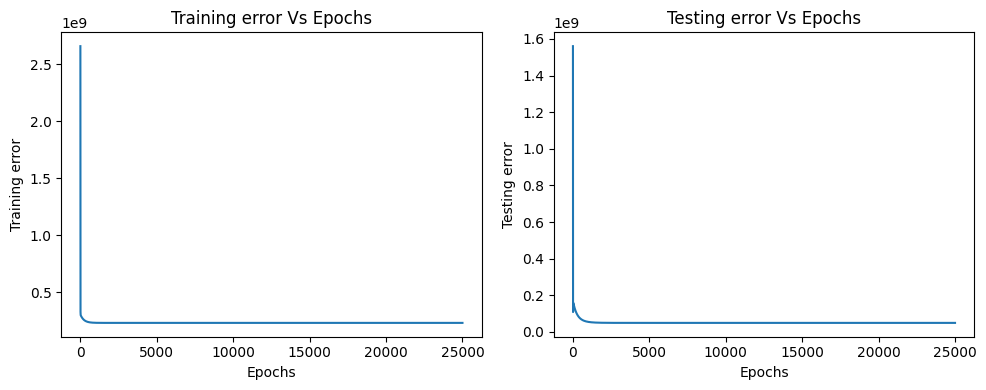

In [ ]:
#import essential library to load dataset
import pandas as pd
#importing the dataset
train_dataset = pd.read_csv('"C:\Users\sanja\Desktop\train_salary.csv"')
test_dataset = pd.read_csv('"C:\Users\sanja\Desktop\test_salary.csv"')
#copy of training dataset excluding the last column
train_input = train_dataset.iloc[:, :-1].values
#copy of last column from training dataset
train_output = train_dataset.iloc[:, -1].values
#copy of testing dataset excluding the last column
test_input = test_dataset.iloc[:, :-1].values
#copy of last column from testing dataset
test_output = test_dataset.iloc[:, -1].values

def hypothesis(sample, parameter):
    pred_output = parameter[0] #calculate theta0*x0 (x0 value is 1)
    for n in range(len(sample)):#calculate the number of features
        pred_output += parameter[n+1] * float((sample[n])) #calculate theta1*x1 + theta2*x2 .. . .thetan*xn
    return pred_output
  
def cost(pred_output,actual_output,m):
  error = (pred_output - float(actual_output))
  mse_error = (1/2*m) * (error**2) #m value is 1 since it is stochastic gradient optimization
  return error,mse_error #error value is for parameter updation and mse_error is to measure the average error at every epoch

def gradient_descent(error,parameters,learning_rate,sample):
  parameters[0] = parameters[0] - (learning_rate * error) #update theta0
  for n in range(sample.size): #calculate the number of features
    parameters[n + 1] = parameters[n + 1] - (learning_rate * error * float(sample[n])) #update theta1, theta2, , ,, depending upon the number of features
  return parameters #return the updated paremeters

def optimization(training_input,training_output,testing_input,testing_output,learning_rate,parameters,epochs,m):
  best_error = 99999999999
  for epoch in range(epochs):
    total_error = 0
    test_error = 0
    for sample, actutal_output in zip(training_input,training_output):#iterate through the training dataset
      predicted_output = hypothesis(sample,parameters) #calculate the per sample predicted output
      error,mse_error = cost(predicted_output,actutal_output,m) #calculate error for each training sample
      parameters = gradient_descent(error,parameters,learning_rate,sample) # update the model parameters
      total_error += mse_error #sumup the error from each training sample
    total_error = (total_error/len(train_input)) #average error
    train_error_list.append(total_error) #append the total error from every epoch to list
    #epochs_num.append(epoch+1)
    testing_error = test_model(testing_input,testing_output,parameters,m) #calculate the error for every testing sample
    test_error += testing_error #sumup the error from each testing sample
    test_error_list.append(test_error)#append the total error from every epoch to list
    if ((epoch+1)%2000==0):#print training progress after every 2000 epochs and replace 2000 by 1 to print progress after every epoch
      print("Epoch:",epoch+1, "Training error:",total_error, "Testing_error:",test_error, "Parameters:",parameters)
    if(best_error > test_error and test_error>=0.0): #copy the best parameter values along with epoch number and testing error for the least testing error during the training
      best_error=test_error
      best_epoch=epoch+1
      best_parameters=parameters
  return best_error,best_epoch,best_parameters

def test_model(testing_input,testing_output,parameters,m):
  total_error = 0
  for sample, actutal_output in zip(testing_input,testing_output):#iterate through the testing dataset
    predicted_output = hypothesis(sample,parameters)#calculate the per sample predicted output
    error,mse_error = cost(predicted_output,actutal_output,m)#calculate error for each testing sample
    total_error += mse_error #sumup the error from each testing sample
  total_error = (total_error/len(test_input))#average error
  return total_error

epochs = 25000
learning_rate = 0.0005
m = 1 #batch_size=1 since its stochastic gradient descent algorithm
#calulate the number of features and initialize all the model parameters to 0
parameters = [0.0 for i in range( len(train_input[0])+1)]
#define the lists for graph plot
train_error_list = [ ]
test_error_list = [ ]
#start the learning algorithm
best_error,best_epoch,best_parameters = optimization(train_input,train_output,test_input,test_output,learning_rate,parameters,epochs,m)
print("\n\n\n-----------------------------------------------------Training Finished-----------------------------------------------------\n")
print("The Best testing error:",best_error,"is at epoch:", best_epoch,"with parameters values",best_parameters)
print("\n---------------------------------------------------------------------------------------------------------------------------")

#import the library to plot the graph
import matplotlib.pyplot as plt
#copy the data for plotting
epochs_num = list(range(1, epochs+1))
x = epochs_num
y1 = train_error_list
y2 = test_error_list
#create a figure with subplots and specify figsize
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
#plot the first subplot for training and add legend and axis labels
axes[0].plot(x, y1)
axes[0].set_title('Training error Vs Epochs')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Training error')
#plot the second subplot for testing and add legend and axis labels
axes[1].plot(x, y2)
axes[1].set_title('Testing error Vs Epochs')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Testing error')
plt.tight_layout()
#show the plots
plt.show()